# Sweep results
Reads `out/*/` (written by `run.py`). Re-run all cells after new runs finish.

In [1]:
import json, glob, os
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)

rows, hists = [], {}
for d in sorted(glob.glob("out/*/")):
    name = os.path.basename(d.rstrip("/"))
    if not (os.path.exists(d+"config.json") and os.path.exists(d+"results.json")):
        continue                                   # still running or failed
    cfg = json.load(open(d+"config.json")); res = json.load(open(d+"results.json"))
    if cfg["model"] == "baselines":                # {baseline: {pair: metrics}}
        for bname, per_pair in res.items():
            for pair, m in per_pair.items():
                rows.append({"run": bname, "model": "baseline", "overrides": "", "min": None, "pair": pair, **m})
    else:                                          # {ALL/pair: metrics}
        hists[name] = json.load(open(d+"history.json"))
        for pair, m in res.items():
            rows.append({"run": name, "model": cfg["model"], "overrides": " ".join(cfg["overrides"]),
                         "min": cfg["minutes"], "pair": pair, **m})
df = pd.DataFrame(rows)
print(len(df.run.unique()), "runs loaded")
print(rows)

19 runs loaded
[{'run': 'all_qw4b_8k_dur02', 'model': 'qwen', 'overrides': 'PAIR_SEL="all" MAX_CONV_PER_PAIR=8000 QWEN_EPOCHS=2 LAMBDA_DUR=0.2 QWEN_NAME="Qwen/Qwen3-4B-Base" QWEN_BATCH_SIZE=8 USE_LORA=True GRAD_CKPT=False QWEN_LR=1e-4', 'min': 379.8, 'pair': 'ALL', 'switch_PR_AUC': 0.831, 'dur_macro_F1': 0.628, 'switch_P': 0.684, 'switch_R': 0.808, 'switch_F1': 0.741, 'dur_R1': 0.75, 'dur_R2': 0.448, 'dur_R3': 0.687, 'switch_F1max': 0.75, 'switch_thr': 0.6267, 'joint_acc': 0.897, 'dur_acc': 0.649, 'dur_MAE': 0.439, 'val_ce_sw': 0.1695, 'val_ce_dur': 0.785, 'val_loss': 0.4006, 'val_loss_sw': 0.2269, 'val_loss_dur': 0.1737}, {'run': 'all_qw4b_8k_dur02', 'model': 'qwen', 'overrides': 'PAIR_SEL="all" MAX_CONV_PER_PAIR=8000 QWEN_EPOCHS=2 LAMBDA_DUR=0.2 QWEN_NAME="Qwen/Qwen3-4B-Base" QWEN_BATCH_SIZE=8 USE_LORA=True GRAD_CKPT=False QWEN_LR=1e-4', 'min': 379.8, 'pair': 'hi-en', 'switch_PR_AUC': 0.869, 'dur_macro_F1': 0.605, 'switch_P': 0.69, 'switch_R': 0.875, 'switch_F1': 0.771, 'dur_R1': 0.8

## Pooled (ALL), sorted by model selection score

In [2]:
cols = ["model","overrides","switch_PR_AUC","switch_F1","switch_F1max","dur_macro_F1","dur_acc","switch_P","switch_R","joint_acc","val_ce_sw","val_ce_dur","min"]
cols = ["model","switch_PR_AUC","switch_F1max","dur_macro_F1","min"]
cols = [k for k in cols if k in df.columns]          # old runs may lack the newer columns
a = df[df.pair=="ALL"].set_index("run")[cols]
a["score"] = 0.5*(a.switch_PR_AUC + a.dur_macro_F1)    # same as trainer.select_score
a.sort_values("score", ascending=False)

,model,switch_PR_AUC,switch_F1max,dur_macro_F1,min,score
run,,,,,,
all_qw4b_8k_dur02,qwen,0.831,0.750,0.628,379.8,0.7295
all_qwen_8k_dur02,qwen,0.815,0.734,0.618,160.9,0.7165
all_qwen_8k_dur05,qwen,0.812,0.732,0.618,160.7,0.7150
all_xlmr_8k_dur02_win32,xlmr,0.810,0.731,0.620,256.7,0.7150
all_xlmr_8k_dur02,xlmr,0.810,0.731,0.619,253.2,0.7145
all_qwen_8k_dur02_seed1,qwen,0.815,0.734,0.614,159.5,0.7145
all_qwen_8k_dur08,qwen,0.810,0.730,0.618,159.7,0.7140
all_xlmr_8k_dur05,xlmr,0.809,0.729,0.618,262.0,0.7135
all_qwen_8k_dur10,qwen,0.808,0.728,0.618,159.5,0.7130


## Per pair

In [3]:
for metric in ["switch_PR_AUC", "switch_F1", "dur_macro_F1", "dur_acc"]:
    if metric not in df.columns: continue
    print("\n==", metric, "==")
    display(df[df.pair!="ALL"].pivot(index="run", columns="pair", values=metric))


== switch_PR_AUC ==


pair,ar-en,de-en,es-en,fr-en,hi-en,it-en,ja-en,ko-en,ru-en,vi-en,yue-en,zh-en
run,,,,,,,,,,,,
B0 always-switch,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
B0 never-switch,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
B1 lookup,0.478,0.433,0.443,0.448,0.509,0.451,0.342,0.575,0.388,0.392,0.246,0.315
B2 char-ngram LR,0.568,0.536,0.523,0.533,0.648,0.536,0.662,0.848,0.522,0.494,0.405,0.457
all_qw4b_8k_dur02,0.819,0.849,0.802,0.820,0.869,0.810,0.866,0.951,0.775,0.748,0.716,0.827
all_qwen_2k_dur02,0.795,0.805,0.773,0.772,0.811,0.785,0.840,0.947,0.719,0.736,0.672,0.773
all_qwen_5k_dur02,0.811,0.833,0.781,0.799,0.843,0.773,0.855,0.949,0.775,0.709,0.679,0.796
all_qwen_8k_dur02,0.802,0.837,0.783,0.804,0.851,0.793,0.854,0.947,0.757,0.730,0.693,0.807
all_qwen_8k_dur02_seed1,0.811,0.839,0.789,0.792,0.854,0.776,0.842,0.943,0.772,0.740,0.690,0.812



== switch_F1 ==


pair,ar-en,de-en,es-en,fr-en,hi-en,it-en,ja-en,ko-en,ru-en,vi-en,yue-en,zh-en
run,,,,,,,,,,,,
B0 always-switch,0.231,0.244,0.227,0.233,0.449,0.221,0.127,0.280,0.237,0.201,0.164,0.151
B0 never-switch,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
B1 lookup,0.376,0.409,0.407,0.408,0.491,0.393,0.395,0.442,0.363,0.406,0.391,0.382
B2 char-ngram LR,0.446,0.427,0.431,0.452,0.594,0.419,0.508,0.664,0.437,0.419,0.390,0.391
all_qw4b_8k_dur02,0.735,0.776,0.725,0.735,0.771,0.735,0.766,0.883,0.700,0.673,0.644,0.742
all_qwen_2k_dur02,0.716,0.746,0.696,0.689,0.722,0.698,0.746,0.865,0.662,0.654,0.618,0.696
all_qwen_5k_dur02,0.724,0.772,0.701,0.723,0.747,0.689,0.763,0.885,0.706,0.650,0.625,0.724
all_qwen_8k_dur02,0.715,0.766,0.709,0.716,0.753,0.716,0.754,0.876,0.692,0.651,0.629,0.730
all_qwen_8k_dur02_seed1,0.719,0.769,0.709,0.714,0.766,0.693,0.747,0.873,0.704,0.664,0.622,0.730



== dur_macro_F1 ==


pair,ar-en,de-en,es-en,fr-en,hi-en,it-en,ja-en,ko-en,ru-en,vi-en,yue-en,zh-en
run,,,,,,,,,,,,
B0 always-switch,0.184,0.187,0.188,0.184,0.250,0.176,0.155,0.183,0.181,0.195,0.162,0.154
B0 never-switch,0.184,0.187,0.188,0.184,0.250,0.176,0.155,0.183,0.181,0.195,0.162,0.154
B1 lookup,0.325,0.310,0.323,0.314,0.359,0.304,0.231,0.326,0.350,0.328,0.319,0.242
B2 char-ngram LR,0.481,0.505,0.503,0.473,0.529,0.480,0.527,0.542,0.483,0.483,0.493,0.464
all_qw4b_8k_dur02,0.606,0.614,0.619,0.613,0.605,0.605,0.599,0.629,0.629,0.597,0.637,0.584
all_qwen_2k_dur02,0.587,0.581,0.536,0.577,0.544,0.564,0.543,0.578,0.597,0.607,0.584,0.542
all_qwen_5k_dur02,0.586,0.604,0.588,0.600,0.582,0.584,0.587,0.615,0.620,0.600,0.588,0.573
all_qwen_8k_dur02,0.591,0.612,0.612,0.605,0.586,0.599,0.567,0.614,0.615,0.589,0.629,0.570
all_qwen_8k_dur02_seed1,0.576,0.600,0.606,0.597,0.578,0.594,0.578,0.616,0.621,0.580,0.618,0.588



== dur_acc ==


pair,ar-en,de-en,es-en,fr-en,hi-en,it-en,ja-en,ko-en,ru-en,vi-en,yue-en,zh-en
run,,,,,,,,,,,,
B0 always-switch,0.380,0.389,0.393,0.381,0.599,0.358,0.304,0.379,0.372,0.413,0.322,0.300
B0 never-switch,0.380,0.389,0.393,0.381,0.599,0.358,0.304,0.379,0.372,0.413,0.322,0.300
B1 lookup,0.428,0.423,0.447,0.426,0.527,0.407,0.324,0.425,0.456,0.453,0.415,0.332
B2 char-ngram LR,0.512,0.542,0.530,0.507,0.622,0.513,0.637,0.594,0.502,0.531,0.501,0.518
all_qw4b_8k_dur02,0.620,0.637,0.629,0.627,0.686,0.616,0.717,0.654,0.631,0.625,0.633,0.649
all_qwen_2k_dur02,0.606,0.622,0.554,0.600,0.661,0.580,0.693,0.617,0.604,0.645,0.579,0.616
all_qwen_5k_dur02,0.605,0.626,0.599,0.618,0.667,0.592,0.710,0.635,0.624,0.622,0.590,0.629
all_qwen_8k_dur02,0.603,0.635,0.622,0.621,0.678,0.611,0.705,0.642,0.616,0.620,0.625,0.632
all_qwen_8k_dur02_seed1,0.596,0.630,0.622,0.614,0.678,0.604,0.709,0.638,0.629,0.615,0.619,0.649


## Training curves (val metrics per epoch, ALL)
Note `val_loss` is not comparable between XLM-R and Qwen3.

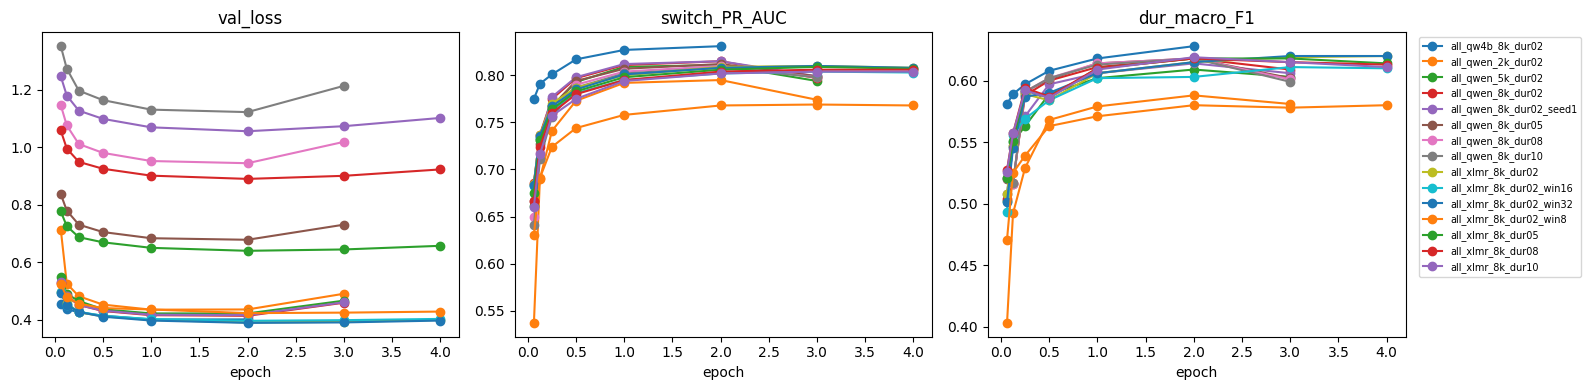

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
def unpack(h):
    # New: {"step","epoch","res"}; Old: one res dict/epoch
    if h and "res" in h[0]:
        return [e["epoch"] for e in h], [e["res"] for e in h]
    return list(range(1, len(h) + 1)), h

for name, h in hists.items():
    ep, rs = unpack(h)
    ax[0].plot(ep, [r["ALL"]["val_loss"] for r in rs], marker="o", label=name)
    ax[1].plot(ep, [r["ALL"]["switch_PR_AUC"] for r in rs], marker="o", label=name)
    ax[2].plot(ep, [r["ALL"]["dur_macro_F1"] for r in rs], marker="o", label=name)
for x, t in zip(ax, ["val_loss", "switch_PR_AUC", "dur_macro_F1"]):
    x.set_title(t); x.set_xlabel("epoch")
ax[2].legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

## Loss convergence: total / Switch / Duration (train vs val)
Shown for the best neural run by `score`; set `RUNS` to plot others. Train loss = average over the steps since the previous validation. Needs runs made with the updated `trainer.py` (older `history.json` has no train loss).

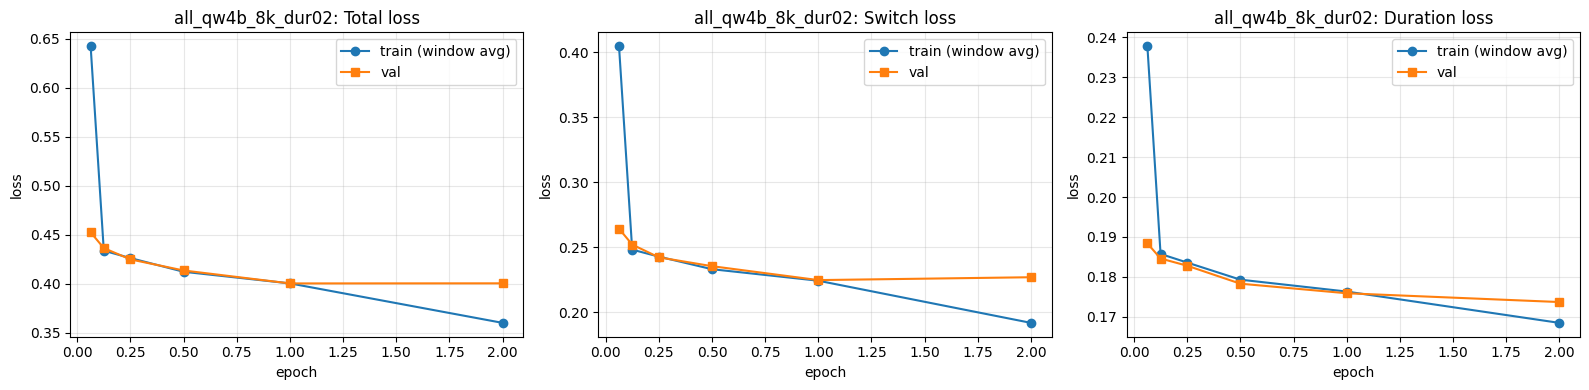

In [5]:
RUNS = [a[a.model != "baseline"].score.idxmax()]      # e.g. RUNS = ["all_qwen_8k_dur03", ...]
# RUNS = ['all_xlmr_8k_dur02']
def plot_run(name):
    h = hists[name]
    if not (h and "train" in h[0]):
        print(name, ": no train loss logged (run predates the update)"); return
    ep = [e["epoch"] for e in h]
    A = lambda k: [e["res"]["ALL"][k] for e in h]
    T = lambda k: [e["train"][k] for e in h]
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    for x, t, tr, va in zip(ax, ["Total loss", "Switch loss", "Duration loss"],
                            ["loss", "loss_sw", "loss_dur"], ["val_loss", "val_loss_sw", "val_loss_dur"]):
        x.plot(ep, T(tr), "o-", label="train (window avg)"); x.plot(ep, A(va), "s-", label="val")
        x.set_title(f"{name}: {t}"); x.set_xlabel("epoch"); x.set_ylabel("loss"); x.legend(); x.grid(alpha=.3)
    plt.tight_layout(); plt.show()

for r in RUNS: plot_run(r)

## Monitored metrics: Switch head (PR-AUC, Anticipatory F1) vs Duration head (Accuracy, Macro-F1)
Anticipatory F1 = positive-class (switch=1) F1; `max` = best threshold on this val set.

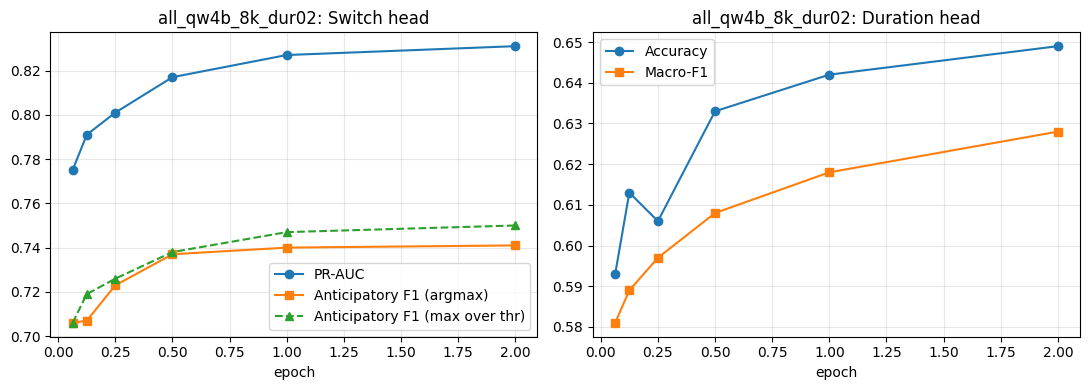

In [6]:
def plot_metrics(name):
    h = hists[name]
    if not (h and "res" in h[0] and "switch_F1max" in h[0]["res"]["ALL"]):
        print(name, ": run predates the updated metrics"); return
    ep = [e["epoch"] for e in h]
    A = lambda k: [e["res"]["ALL"][k] for e in h]
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(ep, A("switch_PR_AUC"), "o-", label="PR-AUC")
    ax[0].plot(ep, A("switch_F1"), "s-", label="Anticipatory F1 (argmax)")
    ax[0].plot(ep, A("switch_F1max"), "^--", label="Anticipatory F1 (max over thr)")
    ax[0].set_title(f"{name}: Switch head")
    ax[1].plot(ep, A("dur_acc"), "o-", label="Accuracy"); ax[1].plot(ep, A("dur_macro_F1"), "s-", label="Macro-F1")
    ax[1].set_title(f"{name}: Duration head")
    for x in ax: x.set_xlabel("epoch"); x.legend(); x.grid(alpha=.3)
    plt.tight_layout(); plt.show()

for r in RUNS: plot_metrics(r)

## Test: Anticipatory F1 and dur_acc per language pair (+ mean / std across pairs)
Reads `out/*/test_results.json`. Neural runs use the switch threshold searched on val; `STD` = sample std (ddof=1) across pairs, `ALL` excluded.


== TEST Anticipatory_F1 ==


pair,ALL,ar-en,de-en,es-en,fr-en,hi-en,it-en,ja-en,ko-en,ru-en,vi-en,yue-en,zh-en,MEAN,STD
run,,,,,,,,,,,,,,,
B0 always-switch,0.219,0.242,0.256,0.226,0.235,0.458,0.220,0.127,0.277,0.242,0.199,0.161,0.148,0.2326,0.0844
B0 never-switch,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0000,0.0000
B1 lookup,0.413,0.384,0.414,0.405,0.407,0.495,0.402,0.397,0.438,0.377,0.409,0.385,0.376,0.4074,0.0327
B2 char-ngram LR,0.468,0.446,0.441,0.428,0.446,0.598,0.411,0.503,0.659,0.451,0.409,0.372,0.389,0.4628,0.0853
all_qw4b_8k_dur02,0.750,0.748,0.787,0.717,0.745,0.779,0.727,0.774,0.883,0.721,0.684,0.634,0.765,0.7470,0.0610
all_qwen_2k_dur02,0.720,0.716,0.759,0.689,0.722,0.742,0.697,0.748,0.871,0.691,0.655,0.596,0.731,0.7181,0.0658
all_qwen_5k_dur02,0.730,0.727,0.770,0.700,0.731,0.754,0.706,0.757,0.877,0.700,0.668,0.602,0.742,0.7278,0.0655
all_qwen_8k_dur02,0.734,0.731,0.770,0.701,0.731,0.763,0.710,0.760,0.879,0.705,0.671,0.615,0.744,0.7317,0.0636
all_qwen_8k_dur02_seed1,0.734,0.731,0.771,0.701,0.735,0.759,0.708,0.762,0.875,0.703,0.674,0.617,0.745,0.7318,0.0623



== TEST dur_acc ==


pair,ALL,ar-en,de-en,es-en,fr-en,hi-en,it-en,ja-en,ko-en,ru-en,vi-en,yue-en,zh-en,MEAN,STD
run,,,,,,,,,,,,,,,
B0 always-switch,0.405,0.401,0.402,0.365,0.382,0.606,0.365,0.310,0.357,0.383,0.406,0.329,0.306,0.3843,0.0777
B0 never-switch,0.405,0.401,0.402,0.365,0.382,0.606,0.365,0.310,0.357,0.383,0.406,0.329,0.306,0.3843,0.0777
B1 lookup,0.432,0.448,0.425,0.417,0.433,0.526,0.425,0.328,0.417,0.470,0.445,0.414,0.336,0.4237,0.0529
B2 char-ngram LR,0.553,0.533,0.528,0.510,0.513,0.623,0.526,0.629,0.569,0.530,0.520,0.518,0.536,0.5446,0.0409
all_qw4b_8k_dur02,0.648,0.635,0.620,0.619,0.622,0.686,0.633,0.718,0.642,0.642,0.613,0.646,0.645,0.6434,0.0303
all_qwen_2k_dur02,0.625,0.609,0.597,0.593,0.602,0.659,0.615,0.701,0.622,0.621,0.595,0.608,0.622,0.6203,0.0310
all_qwen_5k_dur02,0.632,0.619,0.606,0.607,0.611,0.663,0.624,0.703,0.636,0.628,0.599,0.617,0.626,0.6283,0.0289
all_qwen_8k_dur02,0.635,0.620,0.611,0.605,0.612,0.665,0.626,0.711,0.635,0.625,0.604,0.629,0.632,0.6312,0.0300
all_qwen_8k_dur02_seed1,0.636,0.628,0.608,0.605,0.610,0.668,0.622,0.709,0.644,0.630,0.601,0.625,0.630,0.6317,0.0306


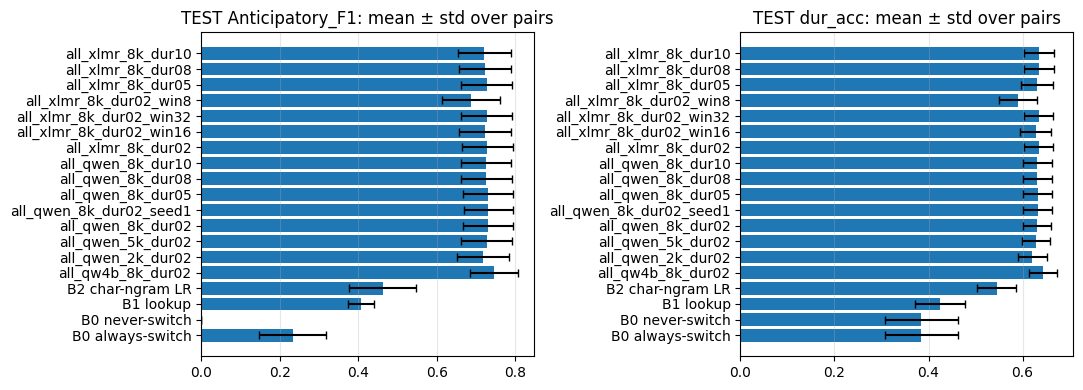

In [7]:
trows = []
for d in sorted(glob.glob("out/*/")):
    p = d + "test_results.json"
    if not os.path.exists(p): continue
    name = os.path.basename(d.rstrip("/")); cfg = json.load(open(d + "config.json")); tr = json.load(open(p))
    for run, per_pair in (tr.items() if cfg["model"] == "baselines" else [(name, tr)]):
        for pair, m in per_pair.items():
            trows.append({"run": run, "pair": pair, "Anticipatory_F1": m["switch_F1"], "dur_acc": m["dur_acc"]})
tdf = pd.DataFrame(trows)

def pair_table(metric):
    t = tdf.pivot(index="run", columns="pair", values=metric)
    pairs = [c for c in t.columns if c != "ALL"]
    t["MEAN"] = t[pairs].mean(axis=1); t["STD"] = t[pairs].std(axis=1, ddof=1)
    return t[["ALL"] + pairs + ["MEAN", "STD"]].round(4)

for metric in ["Anticipatory_F1", "dur_acc"]:
    print("\n== TEST", metric, "==")
    display(pair_table(metric))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for x, metric in zip(ax, ["Anticipatory_F1", "dur_acc"]):
    t = pair_table(metric)
    x.barh(t.index, t["MEAN"], xerr=t["STD"], capsize=3); x.set_title(f"TEST {metric}: mean ± std over pairs"); x.grid(alpha=.3, axis="x")
plt.tight_layout(); plt.show()